# Electronic energy estimation

This notebook uses a verified stored two-qubit H₂ STO-3G Hamiltonian, exact analytic-angle dimer gates, Hartree–Fock preparation and retained-target QPE medians. The quantum accuracy target concerns this finite-basis, fixed-nucleus model. Fresh SCF/mapping and hardware/synthesis certificates are outside this example.

In [1]:
from pathlib import Path
import sys, os, json
candidate = Path.cwd()
for root in (candidate, *list(candidate.parents)[:4]):
    if (root / "src/openquantum").exists():
        sys.path.insert(0, str(root / "src")); break
    if (root / "code/src/openquantum").exists():
        sys.path.insert(0, str(root / "code/src")); break
from openquantum import energy_estimation as energy
from qiskit.quantum_info import Operator, Statevector
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
model = energy.H2_STO3G
print("Fixture:", energy.H2_FIXTURE_PROVENANCE["molecule"], energy.H2_FIXTURE_PROVENANCE["basis"],
      "at", energy.H2_FIXTURE_PROVENANCE["coordinates_angstrom"][1][-1], "angstrom")
print("Stored fixture checkout:", energy.H2_FIXTURE_PROVENANCE["fixture_checkout_tag"],
      "stored execution:", energy.H2_FIXTURE_PROVENANCE["stored_execution_qiskit_nature_version"])

Fixture: H2 sto3g at 0.735 angstrom
Stored fixture checkout: 0.7.2 stored execution: 0.6.0


## Actual Hamiltonian access

CX stores parity. Each parity block has an X/Z axis whose conditional RY/RZ rotations implement evolution directly. The identity/nuclear term and energy-origin phase remain coherent when the circuit is controlled. This diagram is the standalone two-data-qubit access; QPE embeds those data after its clock wires.

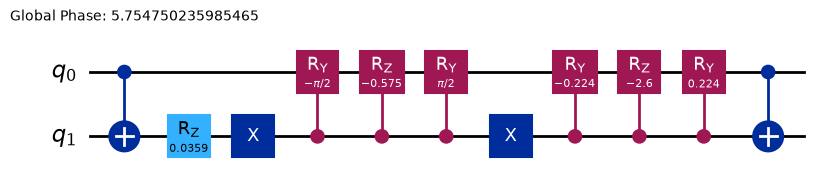

In [2]:
encoding = energy.energy_encoding(model)
access = energy.dimer_evolution(model, -encoding.time)
fig = access.draw(output="mpl", fold=28)
display(fig); plt.close(fig)

In [3]:
from scipy.linalg import expm
H = energy.reference_matrix(model)
expected = expm(1j * encoding.time * (H - encoding.shift * np.eye(4)))
actual = Operator(energy.build_energy_unitary(model)).data
np.testing.assert_allclose(actual, expected, atol=1e-12, rtol=0)
eigenvalues, eigenvectors = np.linalg.eigh(H)
hf_weight = abs(eigenvectors[1, 0])**2
print("Total ground energy (Ha):", eigenvalues[0])
print("Hartree-Fock energy (Ha):", H[1,1].real)
print("Hartree-Fock ground weight:", hf_weight)
print("Energy access matrix discrepancy:", np.linalg.norm(actual-expected, 2))

Total ground energy (Ha):

 -1.1373060357533995
Hartree-Fock energy (Ha): -1.1169989967540035
Hartree-Fock ground weight: 0.9875597343674859
Energy access matrix discrepancy: 1.1749650539548579e-15


## One small QPE round

Three phase bits give a five-wire circuit and seven actual controlled U calls. The first three wires are clocks; model data q0/q1 occupy global wires 3/4. In the resource study, five bits and 19 retained-target rounds are used instead.

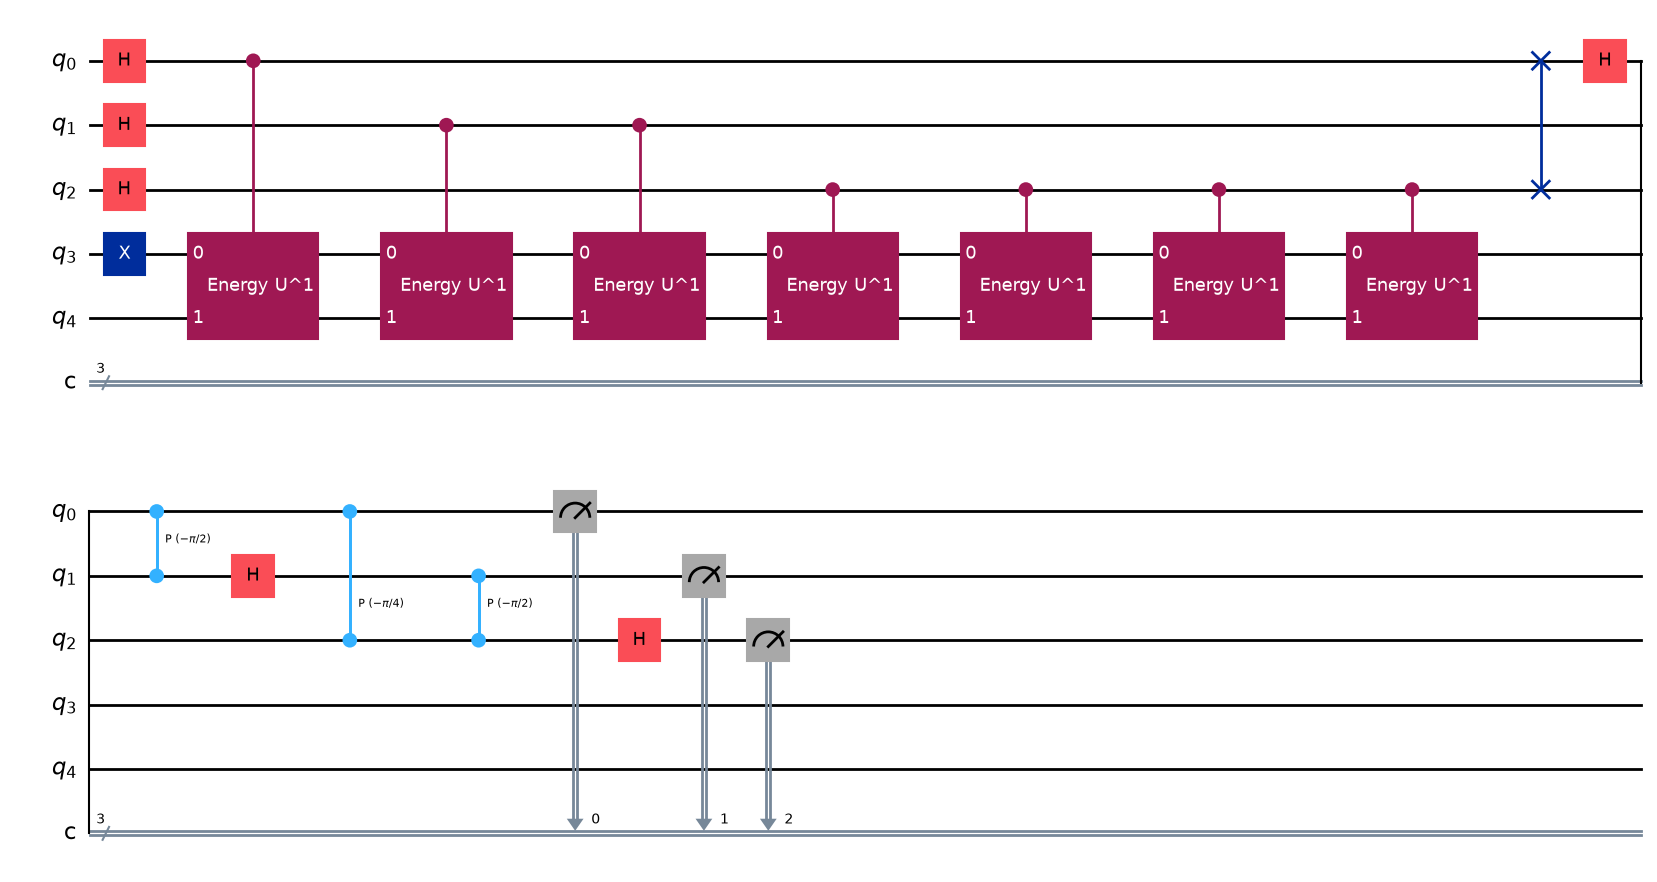

In [4]:
small = energy.build_retained_target_qpe(model, phase_bits=3, rounds=1)
fig = small.draw(output="mpl", fold=24)
display(fig); plt.close(fig)

## Retained-target medians and ground overlap

Repeated rounds inside one group act on the same target. Their joint law is a spectral mixture of conditional IID laws; repeated fresh HF preparations would change that law. We take an odd median in each group, then the minimum across independently prepared groups. No-ground failure plus the union of median failures gives the ideal bound.

In [5]:
contract = energy.ground_energy_contract(model, phase_bits=5, ideal_failure=.005)
R = contract["qpe_rounds_per_retained_target"]
K = contract["independent_groups"]
samples = energy.sample_retained_target_groups(model, phase_bits=5, rounds=R, groups=K, seed=20261112)
reference = energy.reference_spectral_law(model, phase_bits=5)
robust = energy.robust_energy_reference(model, phase_bits=5, rounds=R, groups=K)
error = abs(samples["estimate"] - reference["ground_energy"])
assert robust["ideal_success_within_grid_error"] >= contract["ideal_confidence_lower_bound"] - 1e-12
print("Groups / rounds:", K, R)
print("Ideal absolute energy tolerance (Ha):", contract["energy_absolute_error_ideal"])
print("Ideal confidence lower bound:", contract["ideal_confidence_lower_bound"])
print("Independent exact-law success:", robust["ideal_success_within_grid_error"])
print("Actual sequential gate/projection estimate (Ha):", samples["estimate"])
print("Reference error (Ha):", error)
print("Sequential simulation wires:", samples["simulated_width"], "; complete deferred register allocated:", samples["full_deferred_register_statevector_allocated"])
for group in samples["groups"]:
    print("Group", group["group"], "outcomes", group["outcomes"], "median", group["median_outcome"])

Groups / rounds: 2 19
Ideal absolute energy tolerance (Ha): 0.12351076921585306
Ideal confidence lower bound: 0.9978110023040748
Independent exact-law success: 0.9998425021229457
Actual sequential gate/projection estimate (Ha): -1.1969796358348523
Reference error (Ha): 0.05967360008145284
Sequential simulation wires: 7 ; complete deferred register allocated: False
Group 0 outcomes [10, 9, 9, 10, 9, 9, 9, 10, 9, 9, 9, 9, 8, 9, 10, 9, 10, 9, 9] median 9
Group 1 outcomes [9, 10, 9, 9, 10, 9, 9, 9, 9, 9, 10, 10, 10, 9, 9, 9, 10, 10, 9] median 9


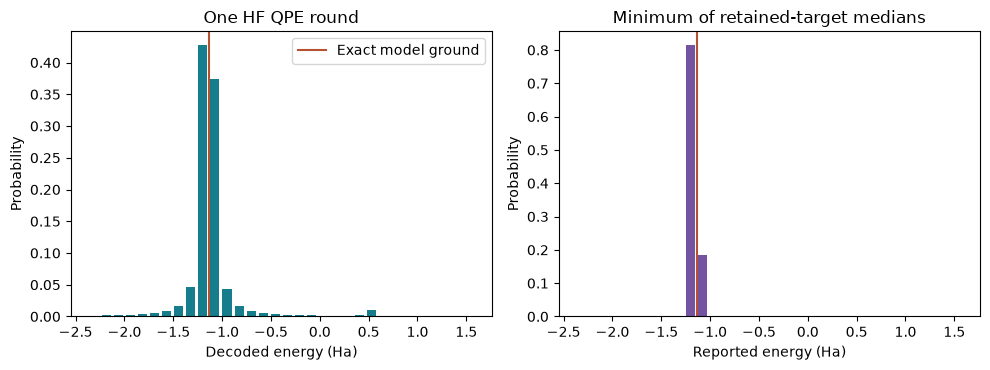

In [6]:
energies = encoding.energy(np.arange(32)/32)
fig, axes = plt.subplots(1,2,figsize=(10,3.8))
axes[0].bar(energies, reference["marginal"], width=encoding.span/32*.75, color="#167d8d")
axes[0].axvline(reference["ground_energy"],color="#b55231",label="Exact model ground")
axes[0].legend(); axes[0].set(xlabel="Decoded energy (Ha)",ylabel="Probability",title="One HF QPE round")
axes[1].bar(robust["energies"],robust["probabilities"],width=encoding.span/32*.75,color="#7353a2")
axes[1].axvline(reference["ground_energy"],color="#b55231")
axes[1].set(xlabel="Reported energy (Ha)",ylabel="Probability",title="Minimum of retained-target medians")
fig.tight_layout(); display(fig); plt.close(fig)

## Complete small-circuit check and recycled clocks

A complete 11-wire, three-round circuit is checked independently. The full default fresh-clock group has 97 wires; its output law is sampled through an equivalent seven-wire sequential instrument, without claiming full 97-wire statevector simulation. The implemented reset circuit reduces live width but still pays all rounds and initialization/reset/readout work; its physical instrument model is pending.

In [7]:
joint_actual = energy.simulate_complete_group(model, phase_bits=3, rounds=3)
joint_reference = energy.joint_reference_distribution(model, phase_bits=3, rounds=3)
np.testing.assert_allclose(joint_actual, joint_reference, atol=1e-12, rtol=0)
print("Complete 11-wire joint discrepancy:", np.max(np.abs(joint_actual-joint_reference)))
recycled = energy.build_recycled_clock_qpe(model,phase_bits=5,rounds=R)
print("Recycled width:", recycled.num_qubits, "source resets/group:", recycled.count_ops()["reset"],
      "clock readouts/group:", recycled.count_ops()["measure"])
print("Physical reset/instrument estimate:", recycled.metadata["physical_resource_estimate"])

Complete 11-wire joint discrepancy: 4.718447854656915e-16
Recycled width: 7 source resets/group: 97 clock readouts/group: 95
Physical reset/instrument estimate: unsupported_dynamic_instrument


In [8]:
artifact = root / "assets/generated/energy-estimation/logical-resources.json"
if artifact.exists():
    ledger = json.loads(artifact.read_text())
    report_path = artifact.parent / "surface-code.json"
    report = json.loads(report_path.read_text()) if report_path.exists() else None
    rows = ["| Quantity | Recorded value |", "|---|---:|",
            f"| Static logical wires/group | {ledger['logical_qubits_per_group']} |",
            f"| Primitive operations/group | {ledger['primitive_operations_per_group']:,} |",
            f"| All-group primitive operations | {ledger['primitive_operations_all_groups']:,} |",
            f"| All-group phase readouts | {ledger['qubit_measurements_all_groups']} |",
            f"| HF preparations | {ledger['hartree_fock_preparations_all_groups']} |"]
    if report and report.get('pareto_points'):
        point=min(report['pareto_points'],key=lambda p:p['peak_physical_qubits'])
        rows += [f"| Conditional fewest peak physical qubits | {point['peak_physical_qubits']:,} |",
                 f"| Conditional all-group runtime (s) | {point['serial_runtime_all_executions_ns']/1e9:.6g} |"]
    display(Markdown("\n".join(rows)))
    print("Physical model excludes initialization, SCF/mapping, classical communication and a synthesis certificate.")
else:
    print("Prebuilt resource ledger unavailable. Run the public generator in the full locked environment for conditional estimates.")

| Quantity | Recorded value |
|---|---:|
| Static logical wires/group | 97 |
| Primitive operations/group | 153,903 |
| All-group primitive operations | 307,806 |
| All-group phase readouts | 190 |
| HF preparations | 2 |
| Conditional fewest peak physical qubits | 57,243 |
| Conditional all-group runtime (s) | 6.97873 |

Physical model excludes initialization, SCF/mapping, classical communication and a synthesis certificate.


## Optional live resolution control

A local/Binder kernel can regenerate one actual QPE round and check its distribution against the independent spectral law. The static build omits widget objects. The control demonstrates one round; it does not replace the grouped confidence/resource protocol.

In [9]:
if os.environ.get("OPENQUANTUM_STATIC_BUILD") != "1":
    from ipywidgets import interact, IntSlider
    def inspect_resolution(phase_bits=3):
        probabilities=energy.simulate_complete_group(model,phase_bits=phase_bits,rounds=1)
        ref=energy.reference_spectral_law(model,phase_bits=phase_bits)
        np.testing.assert_allclose(probabilities,ref["marginal"],atol=1e-12,rtol=0)
        fig,ax=plt.subplots(figsize=(8,3))
        ax.bar(encoding.energy(np.arange(2**phase_bits)/2**phase_bits),probabilities,
               width=encoding.span/2**phase_bits*.7,color="#167d8d")
        ax.axvline(ref["ground_energy"],color="#b55231")
        ax.set(xlabel="Decoded energy (Ha)",ylabel="Probability",title=f"One QPE round; ideal grid error {encoding.span/2**phase_bits:.4g} Ha")
        display(fig);plt.close(fig)
    interact(inspect_resolution,phase_bits=IntSlider(value=3,min=2,max=5,description="Clock bits"))
else:
    print("Live controls omitted from static execution.")

Live controls omitted from static execution.


## Reproduce and inspect

Use Python 3.12 and the included lock/public package. Core simulation uses Qiskit, NumPy/SciPy and Matplotlib; Binder's smaller environment does not run QDK estimates. `python scripts/generate_energy_estimation.py --no-estimate` produces logical/simulation artifacts without QDK. The full lock enables conditional resource models. Actual higher-resolution dimer powers are generated by `--analytic-powers --phase-bits 12 --no-sim --no-scaling --no-estimate`; those exports do not establish hardware chemical accuracy. Nature data are credited at exact pinned sources; original circuit code/figures are MIT. No Lean proof or synthesized error certificate is included.